# Shallow Velocity Model (Model Training)

This notebook is used to estimate the GP hyper-parameters for the shallow velocity model to improve the LA basin in UCVM

### Load Packages

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams as rc
import matplotlib
import os
import math
import matplotlib.colors as mcolors
import torch
import gpytorch
from pyproj import Proj, transform
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
from pickle import dump, load
import linear_operator
import random
from sklearn.cluster import KMeans
import geopandas as gpd
from shapely.geometry import Polygon

#import user models

from pylib_gp_noconst    import VelGPModelStationary
from pylib_gp_noconst    import VelGPModelStationaryConstrainedNoise
from pylib_gp_noconst    import VelGPModelStationaryConstrainedNoiseScaleSum
from pylib_gp_noconst    import KernelStationary

from newloss import LeaveGroupOutPseudoLikelihood

configs = {
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'font.sans-serif': ['Arial'],
     #'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    #'font.sans-serif': ['Palatino Linotype', 'Microsoft YaHei', 'SimHei', 'Arial', 'Liberation Sans', 'sans-serif'],
    'axes.grid': True,
    'grid.alpha': 0.5,
    'grid.linestyle': '--',
    'mathtext.fontset': "cm",
    # 'mathtext.rm': "asana math",
    # 'mathtext.cal': "asana math",
    "font.size": 20,
    # 'axes.labelsize': 'large',
    # 'axes.labelpad': 8.0,
    # 'xtick.major.pad': 9.0,
}
rc.update(configs)

In [2]:
cmap = matplotlib.colormaps.get_cmap("coolwarm")
red_color = cmap(0.9)
blue_color = cmap(0.1)
gray_color = cmap(0.5)

color_maps = {
    "input": gray_color,
    "Expected": red_color,
    "Predicted": blue_color,
}

### Define Variables

* define model name

In [3]:
#model column names (input, output)
cn_x = ['vs_depth','Z_2.5','surf_elevation','easting','northing'] #output
cn_y = 'diff'                                                     #input

#data percentiles for test1 and test2
prc_test1 = 0.05
prc_test2 = 0.05

#define random seed
np.random.seed(1)

#define output directories
dir_out = '../Data/Vel_data/'
dir_fig = '../Data/Figure/'
dir_model = './'

#define iteration numbers
iter_num = 2500

# container for hyper parameters
hyper_parameters = {
    'stat_z':         [],
    'stat_z2.5':      [],
    'stat_elevation': [],
    'stat_scale':     [],
    'stat_scale_id':     [],
    'noise':         []}

### Read Input Files

In [4]:
#read the entire data
df_measure = pd.read_csv(dir_out+'Training_data/df_measure.txt', encoding='utf-8')
df_measure = df_measure.rename(columns={'metadata_id': 'velocity_metadata_id', 'z_2.5': 'Z_2.5',
                                       'vs_middle_depth': 'vs_depth'})
df_measure

,velocity_metadata_id,vs_depth,vs_value,vs_top_depth,vs_bottom_depth,test_id,velocity_name,velocity_method,velocity_date,velocity_quality,...,terrain_class,site_easting,site_northing,test_easting,test_northing,vs_model,surf_elevation,Z_2.5,diff,basin_idnum
0,610,1.00,155.0,0.5,1.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,938.187,251.052,2380.0,-1.800524,2
1,610,2.00,170.2,1.5,2.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,939.068,251.052,2380.0,-1.707914,2
2,610,3.00,196.5,2.5,3.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,939.949,251.052,2380.0,-1.565163,2
3,610,4.00,191.9,3.5,4.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,940.830,251.052,2380.0,-1.589788,2
4,610,5.00,202.0,4.5,5.5,542,ELC,Suspension Logging,1996-09-26,NaN,...,4,352134.046903,3.786794e+06,352134.046903,3.786794e+06,941.711,251.052,2380.0,-1.539431,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11026,2479,12.60,354.0,9.3,15.9,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,894.882,54.938,3620.0,-0.927395,1
11027,2479,21.15,387.0,15.9,26.4,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,899.010,54.938,3620.0,-0.842869,1
11028,2479,34.80,445.0,26.4,43.2,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,905.600,54.938,3620.0,-0.710523,1
11029,2479,56.60,540.0,43.2,70.0,2419,VS,MASW,NaN,NaN,...,8,400420.745906,3.762835e+06,400420.745906,3.762835e+06,916.125,54.938,3620.0,-0.528584,1


In [5]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

coords = df_measure[["site_easting", "site_northing"]].to_numpy()

kmeans = KMeans(n_clusters=50, random_state=0, n_init=10)
labels = kmeans.fit_predict(coords)

group_index = torch.tensor(labels, dtype=torch.long, device=device)

groups = [
    torch.tensor(np.where(labels == g)[0], dtype=torch.long, device=device)
    for g in range(50)
]

In [6]:
df_measure = df_measure[['vs_depth','Z_2.5','surf_elevation','site_easting','site_northing','diff',  'velocity_metadata_id','vs30','basin_idnum']]
df_measure = df_measure.rename(columns={'site_easting': 'easting', 'site_northing': 'northing', 'diff_smooth': 'diff'})
df_measure

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum
0,1.00,2380.0,251.052,352134.046903,3.786794e+06,-1.800524,610,295.692,2
1,2.00,2380.0,251.052,352134.046903,3.786794e+06,-1.707914,610,295.692,2
2,3.00,2380.0,251.052,352134.046903,3.786794e+06,-1.565163,610,295.692,2
3,4.00,2380.0,251.052,352134.046903,3.786794e+06,-1.589788,610,295.692,2
4,5.00,2380.0,251.052,352134.046903,3.786794e+06,-1.539431,610,295.692,2
...,...,...,...,...,...,...,...,...,...
11026,12.60,3620.0,54.938,400420.745906,3.762835e+06,-0.927395,2479,304.365,1
11027,21.15,3620.0,54.938,400420.745906,3.762835e+06,-0.842869,2479,304.365,1
11028,34.80,3620.0,54.938,400420.745906,3.762835e+06,-0.710523,2479,304.365,1
11029,56.60,3620.0,54.938,400420.745906,3.762835e+06,-0.528584,2479,304.365,1


In [7]:
df_sonic = pd.read_csv(dir_out+'Training_data/df_sonic.txt', encoding='utf-8')
df_sonic = df_sonic.rename(columns={'X': 'easting', 'Y': 'northing',
                                       'depth': 'vs_depth'})
df_sonic

,DEPTH_m,velocity_mps,easting,northing,source_file,TVDSS,velocity,velocity_metadata_id,longitude,latitude,vs_UCVM,vp_UCVM,surf_elevation,ratio,vs,vs_depth,Z_2.5,diff,basin_idnum
0,43.5280,1713.535764,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,43.528000,1702.435158,-29,-118.218003,33.912748,867.819,1684.427,23.596,0.515201,877.096827,67.124000,4400.0,0.010634,1
1,53.5280,1756.154846,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,53.528000,1723.341882,-29,-118.218003,33.912748,871.262,1692.589,23.596,0.514751,887.092079,77.124000,4400.0,0.018006,1
2,63.5280,1738.138676,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,63.528000,1750.140249,-29,-118.218003,33.912748,874.706,1700.750,23.596,0.514306,900.107703,87.124000,4400.0,0.028627,1
3,73.5280,1699.290684,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,73.528000,1779.210020,-29,-118.218003,33.912748,878.150,1708.912,23.596,0.513865,914.273689,97.124000,4400.0,0.040313,1
4,83.5280,1748.027201,387402.0000,3753149.500,HVD_CVMH_soccom_1.las,83.528000,1806.930958,-29,-118.218003,33.912748,881.593,1717.073,23.596,0.513428,927.728573,107.124000,4400.0,0.051009,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3177,1956.3772,3072.301908,387298.0938,3767711.984,tuo_2,1873.377197,3072.714253,-28,-118.221002,34.044045,2107.562,3453.733,83.353,0.610227,1875.053977,1956.730197,2500.0,-0.116894,1
3178,1966.3772,3274.496954,387298.0938,3767711.984,tuo_2,1883.377197,3273.990138,-28,-118.221002,34.044045,2115.348,3464.896,83.353,0.610508,1998.798374,1966.730197,2500.0,-0.056673,1
3179,1976.3772,3338.298432,387298.0938,3767711.984,tuo_2,1893.377197,3338.257238,-28,-118.221002,34.044045,2123.133,3476.058,83.353,0.610788,2038.966008,1976.730197,2500.0,-0.040450,1
3180,1986.3772,3316.756804,387298.0938,3767711.984,tuo_2,1903.377197,3316.470704,-28,-118.221002,34.044045,2130.919,3487.221,83.353,0.611065,2026.579456,1986.730197,2500.0,-0.050204,1


In [8]:
df_sonic = df_sonic[['vs_depth','Z_2.5','surf_elevation','easting','northing','diff',  'velocity_metadata_id']]
df_sonic

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id
0,67.124000,4400.0,23.596,387402.0000,3753149.500,0.010634,-29
1,77.124000,4400.0,23.596,387402.0000,3753149.500,0.018006,-29
2,87.124000,4400.0,23.596,387402.0000,3753149.500,0.028627,-29
3,97.124000,4400.0,23.596,387402.0000,3753149.500,0.040313,-29
4,107.124000,4400.0,23.596,387402.0000,3753149.500,0.051009,-29
...,...,...,...,...,...,...,...
3177,1956.730197,2500.0,83.353,387298.0938,3767711.984,-0.116894,-28
3178,1966.730197,2500.0,83.353,387298.0938,3767711.984,-0.056673,-28
3179,1976.730197,2500.0,83.353,387298.0938,3767711.984,-0.040450,-28
3180,1986.730197,2500.0,83.353,387298.0938,3767711.984,-0.050204,-28


In [9]:
df_veldata = pd.concat([df_measure.reset_index(drop=True), df_sonic.reset_index(drop=True)], ignore_index=True, sort=False)
df_veldata

,vs_depth,Z_2.5,surf_elevation,easting,northing,diff,velocity_metadata_id,vs30,basin_idnum
0,1.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.800524,610,295.692,2.0
1,2.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.707914,610,295.692,2.0
2,3.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.565163,610,295.692,2.0
3,4.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.589788,610,295.692,2.0
4,5.000000,2380.0,251.052,352134.046903,3.786794e+06,-1.539431,610,295.692,2.0
...,...,...,...,...,...,...,...,...,...
14208,1956.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.116894,-28,NaN,NaN
14209,1966.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.056673,-28,NaN,NaN
14210,1976.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.040450,-28,NaN,NaN
14211,1986.730197,2500.0,83.353,387298.093800,3.767712e+06,-0.050204,-28,NaN,NaN


In [10]:
# get seperate files
_, vp_idx = np.unique(df_veldata.velocity_metadata_id, return_index=True)

df_velprof = df_veldata.loc[vp_idx,['velocity_metadata_id','vs_depth',
                                    'easting','northing',
                                    'Z_2.5','surf_elevation']].reset_index(drop=True)
df_velprof

,velocity_metadata_id,vs_depth,easting,northing,Z_2.5,surf_elevation
0,-33,311.393996,382795.562000,3.761978e+06,5560.0,50.832
1,-32,90.718797,382795.562000,3.761978e+06,5560.0,50.832
2,-31,377.859422,391833.750000,3.760684e+06,5200.0,41.571
3,-30,91.229801,397158.781000,3.757608e+06,4180.0,42.063
4,-29,67.124000,387402.000000,3.753150e+06,4400.0,23.596
...,...,...,...,...,...,...
656,2475,0.750000,494570.169822,3.762546e+06,2500.0,733.439
657,2476,0.450000,420063.686658,3.764811e+06,1840.0,182.872
658,2477,0.500000,431943.461780,3.775829e+06,940.0,392.528
659,2478,0.450000,431258.939147,3.773018e+06,800.0,332.537


findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

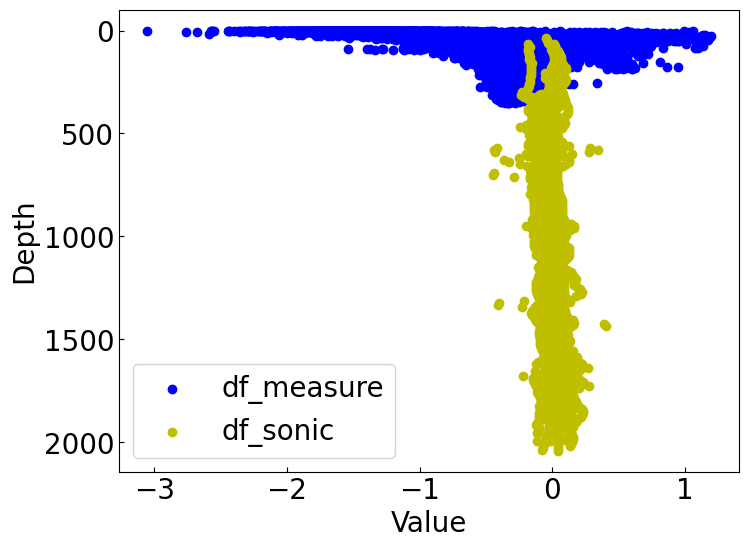

In [11]:
plt.figure(figsize=(8, 6))
plt.scatter(df_measure['diff'], df_measure['vs_depth'], color='b', label="df_measure")
plt.scatter(df_sonic['diff'], df_sonic['vs_depth'], color='y', label="df_sonic")
plt.gca().invert_yaxis()
plt.xlabel("Value")
plt.ylabel("Depth")
plt.legend()
plt.grid()
plt.show()

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

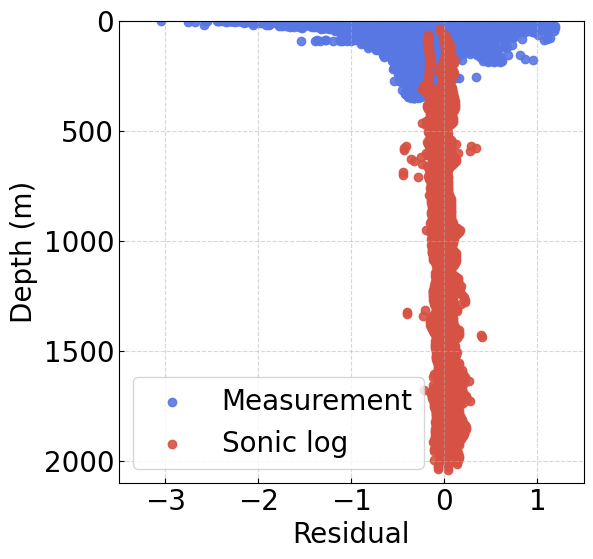

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.scatter(df_measure['diff'], df_measure['vs_depth'],  color=blue_color, label="Measurement",alpha=0.9)
ax.scatter(df_sonic['diff'], df_sonic['vs_depth'],  color=red_color,label="Sonic log",alpha=0.9)

ax.set( xlim=(-3.5, 1.5), ylim=(0, 2100),
       xlabel="Residual",
       ylabel="Depth (m)")
ax.invert_yaxis()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

ax.legend()
#fig.savefig(dir_fig+'vs_data_combine.png', format='png', dpi=300)

### Data Normalization

In [13]:
#initialize standardization
scaler_input  = StandardScaler()

#fit standardization
scaler_input.fit(df_measure.loc[:,cn_x].values)

#assume same scale for easting & northing
scaler_input.scale_[3:5] = np.mean(scaler_input.scale_[3:5])

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

X_train = scaler_input.transform(df_measure.loc[:,cn_x].values)
#get output
Y_train = df_measure.loc[:,cn_y].values



In [14]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
device

device(type='cuda', index=0)

In [15]:
X_train.shape

(11031, 5)

In [16]:
X_train

array([[-0.82574082, -0.18537256,  0.23794604, -1.05467208,  0.50505122],
       [-0.80968844, -0.18537256,  0.23794604, -1.05467208,  0.50505122],
       [-0.79363606, -0.18537256,  0.23794604, -1.05467208,  0.50505122],
       ...,
       [-0.28317047,  0.69628348, -0.79325012,  0.61973054, -0.32574782],
       [ 0.06677136,  0.69628348, -0.79325012,  0.61973054, -0.32574782],
       [ 0.3621351 ,  0.69628348, -0.79325012,  0.61973054, -0.32574782]])

In [17]:
#change into tensor type
dtype = torch.float32


X_train = torch.tensor(X_train, dtype=torch.float32).to(device)
Y_train = torch.tensor(Y_train, dtype=torch.float32).to(device)
#Y_train.var().detach().cpu().numpy()

basin_col = torch.tensor(
    df_measure['basin_idnum'].to_numpy(),
    dtype=X_train.dtype,
    device=X_train.device
).unsqueeze(1)

X_train = torch.cat([X_train, basin_col], dim=1)

In [18]:
X_train

tensor([[-0.8257, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        [-0.8097, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        [-0.7936, -0.1854,  0.2379, -1.0547,  0.5051,  2.0000],
        ...,
        [-0.2832,  0.6963, -0.7933,  0.6197, -0.3257,  1.0000],
        [ 0.0668,  0.6963, -0.7933,  0.6197, -0.3257,  1.0000],
        [ 0.3621,  0.6963, -0.7933,  0.6197, -0.3257,  1.0000]],
       device='cuda:0')

In [19]:
Y_train.var().detach().cpu().numpy()

array(0.26898038, dtype=float32)

In [20]:
stat_params_lengthscale_depth_inital = 1.0
stat_params_lengthscale_z25_inital   = 1.0
stat_params_lengthscale_selev_inital = 1.0
stat_params_scale_init               = 0.1
stat_params_scale_init_id             = 0.1
noise_init                           = 0.1
noise_min = 0.1
#max_total = 1.0
max_total = Y_train.var().detach().cpu().numpy()   

#define likelihood and model
likelihood = gpytorch.likelihoods.GaussianLikelihood().to(device=device, dtype = dtype)

# model = VelGPModelStationaryConstrainedNoise(X, Y, likelihood, noise_min).to(device).double()

model = VelGPModelStationaryConstrainedNoiseScaleSum(X_train, Y_train, likelihood, noise_min, max_total,
                                                     stat_params_lengthscale_depth_inital,
                                                     stat_params_lengthscale_z25_inital,
                                                     stat_params_lengthscale_selev_inital,
                                                     stat_params_scale_init,
                                                     stat_params_scale_init_id,
                                                     noise_init).to(device=device, dtype = dtype)

'''

model = VelGPModelStationaryConstrainedNoiseScaleSum(X_train, Y_train, likelihood, noise_min, stat_params_lengthscale_depth_inital, stat_params_lengthscale_z25_inital,
                                                     stat_params_lengthscale_selev_inital,
                                                     stat_params_scale_init,  noise_init).to(device).double()
'''
optimizer = torch.optim.Adam(model.parameters(), lr=0.1/100)


In [21]:

rbf_z_param = model.covar_module.rbf_z.raw_lengthscale
base_params = [p for p in model.parameters() if id(p) != id(rbf_z_param)]
optimizer = torch.optim.Adam([
    {'params': base_params, 'lr': 0.02},
    {'params': [rbf_z_param], 'lr': 0.1},
])

In [22]:
#find optimal model hyperparameters
model.train()
likelihood.train()

#adam optimizer
#optimizer = torch.optim.Adam(model.parameters(), lr=0.1)
#the marginal log likelihood
#mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)
mll = LeaveGroupOutPseudoLikelihood(likelihood, model, groups)
#loo_quad = LeaveOneOutQuadratic(likelihood, model)
#training iterations
loss_list = []  

for i in range(iter_num):
    #zero gradients from previous iteration
    optimizer.zero_grad()
    #inccrease iteration numbers avoid non-convergence
    with linear_operator.settings.max_cg_iterations(2000), linear_operator.settings.cg_tolerance(1e-3):
        #output from model
        output = model(X_train)
    #loss and backprop gradients
    #loss = -loo_quad(output, Y_train)
    loss = -mll(output, Y_train)
    loss.backward()
    loss_list.append(loss.item()) 
    print(f"Iteration {i+1} - Loss: {loss.item():.6f}")
    optimizer.step()
    model.enforce_total_variance()

    stat_depth_lengthscale  = model.covar_module.rbf_z.lengthscale.item()
    stat_params_lengthscale = model.covar_module.rbf_params.lengthscale.detach().squeeze().cpu().numpy()
    stat_params_scale       = model.covar_module.rbf_params_scl.outputscale.item()
    stat_params_scale_id       = model.covar_module.kid_scl.outputscale.item()
    noise                   = model.likelihood.noise.item()

    hyper_parameters['stat_z'].append(stat_depth_lengthscale)
    hyper_parameters['stat_z2.5'].append(stat_params_lengthscale[0])
    hyper_parameters['stat_elevation'].append(stat_params_lengthscale[1])
    hyper_parameters['stat_scale'].append(stat_params_scale)
    hyper_parameters['stat_scale_id'].append(stat_params_scale_id)
    hyper_parameters['noise'].append(noise)


df_hyper_parameters = pd.DataFrame(hyper_parameters)

Iteration 1 - Loss: 0.392288
Iteration 2 - Loss: 0.396984
Iteration 3 - Loss: 0.392369
Iteration 4 - Loss: 0.387861
Iteration 5 - Loss: 0.383564
Iteration 6 - Loss: 0.379579
Iteration 7 - Loss: 0.375959
Iteration 8 - Loss: 0.372679
Iteration 9 - Loss: 0.369638
Iteration 10 - Loss: 0.366745
Iteration 11 - Loss: 0.363981
Iteration 12 - Loss: 0.361370
Iteration 13 - Loss: 0.358905
Iteration 14 - Loss: 0.356549
Iteration 15 - Loss: 0.354262
Iteration 16 - Loss: 0.352011
Iteration 17 - Loss: 0.349772
Iteration 18 - Loss: 0.347533
Iteration 19 - Loss: 0.345298
Iteration 20 - Loss: 0.343084
Iteration 21 - Loss: 0.340910
Iteration 22 - Loss: 0.338789
Iteration 23 - Loss: 0.336744
Iteration 24 - Loss: 0.334751
Iteration 25 - Loss: 0.332795
Iteration 26 - Loss: 0.330865
Iteration 27 - Loss: 0.328949
Iteration 28 - Loss: 0.327039
Iteration 29 - Loss: 0.325130
Iteration 30 - Loss: 0.323219
Iteration 31 - Loss: 0.321307
Iteration 32 - Loss: 0.319397
Iteration 33 - Loss: 0.317493
Iteration 34 - Loss

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

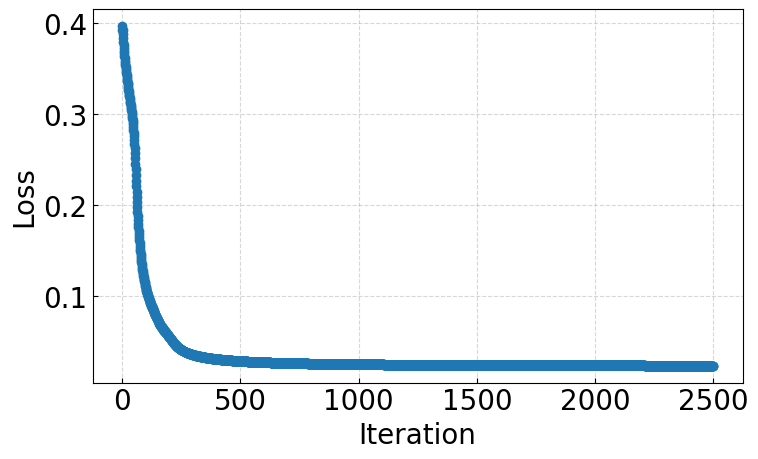

In [23]:
#plot loss function
plt.figure(figsize=(8, 5))
plt.plot(range(0, iter_num), loss_list, marker='o')
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Arial
findfont: Generic family 'sans-serif' not found because

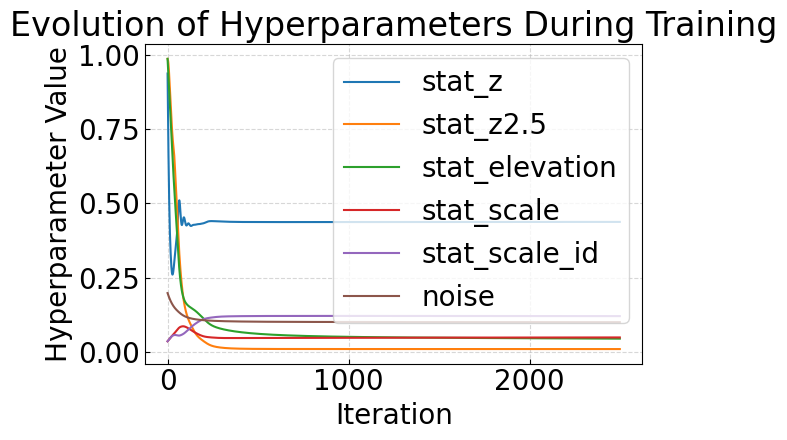

In [24]:
for name, values in hyper_parameters.items():
    plt.plot(values, label=name)

plt.xlabel("Iteration")
plt.ylabel("Hyperparameter Value")
plt.title("Evolution of Hyperparameters During Training")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
n = min([len(loss_list)] + [len(v) for v in hyper_parameters.values()])

data = {k: v[:n] for k, v in hyper_parameters.items()}
df_hist = pd.DataFrame(data)
df_hist.insert(0, "iteration", np.arange(1, n + 1))
df_hist["loss"] = loss_list[:n]
df_hist['sum'] = df_hist['noise'] + df_hist['stat_scale'] + df_hist['stat_scale_id']

df_hist

,iteration,stat_z,stat_z2.5,stat_elevation,stat_scale,stat_scale_id,noise,loss,sum
0,1,0.937961,0.987404,0.987404,0.035482,0.035482,0.198016,0.392288,0.268980
1,2,0.878278,0.983885,0.975190,0.036184,0.036179,0.196168,0.396984,0.268531
2,3,0.820935,0.982381,0.962999,0.036902,0.036894,0.194354,0.392369,0.268150
3,4,0.766152,0.980145,0.950801,0.037634,0.037624,0.192575,0.387861,0.267832
4,5,0.714236,0.975851,0.938600,0.038377,0.038364,0.190829,0.383564,0.267571
...,...,...,...,...,...,...,...,...,...
2495,2496,0.437830,0.009325,0.044417,0.048509,0.120373,0.100098,0.023152,0.268980
2496,2497,0.437833,0.009325,0.044414,0.048509,0.120373,0.100098,0.023150,0.268980
2497,2498,0.437839,0.009326,0.044411,0.048510,0.120372,0.100098,0.023151,0.268980
2498,2499,0.437845,0.009326,0.044407,0.048511,0.120372,0.100098,0.023149,0.268980


### Save Transformations and GP

In [26]:
#save input transformation
dump(scaler_input, open(dir_model+'ucvm_la_basin_adj_scaler.pkl', 'wb'))

#save gp model
torch.save(model.state_dict(), dir_model+'ucvm_la_basin_adj_model_sta.pth')

### Output hyperparameters

In [27]:
df_hist.to_csv(dir_out+'Hyperparameters/vs_data_hyper_step1.txt', index=False,
                  encoding='utf-8',
                  lineterminator='\n')